# Import Library

In [2]:
# 202431076_AimeeJehovaJireh

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Membaca Dataset Bank Customer

In [24]:
# 202431076_AimeeJehovaJireh

df = pd.read_csv("bank_customers.csv")

print("Dataset berhasil dibaca.")

display(df.head())

Dataset berhasil dibaca.


,"age;""job"";""marital"";""education"";""default"";""balance"";""housing"";""loan"";""contact"";""day"";""month"";""duration"";""campaign"";""pdays"";""previous"";""poutcome"";""y"""
0,"58;""management"";""married"";""tertiary"";""no"";2143..."
1,"44;""technician"";""single"";""secondary"";""no"";29;""..."
2,"33;""entrepreneur"";""married"";""secondary"";""no"";2..."
3,"47;""blue-collar"";""married"";""unknown"";""no"";1506..."
4,"33;""unknown"";""single"";""unknown"";""no"";1;""no"";""n..."


# Memeriksa Ukuran dan Struktur Dataset

In [4]:
# 202431076_AimeeJehovaJireh

print("Ukuran dataset:", df.shape)

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe(include="all").T)

Ukuran dataset: (45211, 1)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 1 columns):
 #   Column                                                                                                                                                Non-Null Count  Dtype 
---  ------                                                                                                                                                --------------  ----- 
 0   age;"job";"marital";"education";"default";"balance";"housing";"loan";"contact";"day";"month";"duration";"campaign";"pdays";"previous";"poutcome";"y"  45211 non-null  object
dtypes: object(1)
memory usage: 353.3+ KB

Statistik deskriptif:


,count,unique,top,freq
"age;""job"";""marital"";""education"";""default"";""balance"";""housing"";""loan"";""contact"";""day"";""month"";""duration"";""campaign"";""pdays"";""previous"";""poutcome"";""y""",45211,45211,"58;""management"";""married"";""tertiary"";""no"";2143...",1


# Memeriksa Missing Value dan Data Duplikat

In [5]:
# 202431076_AimeeJehovaJireh

print("Missing value per kolom:")
display(df.isnull().sum())

print("Jumlah baris duplikat:", df.duplicated().sum())

Missing value per kolom:


age;"job";"marital";"education";"default";"balance";"housing";"loan";"contact";"day";"month";"duration";"campaign";"pdays";"previous";"poutcome";"y"    0
dtype: int64

Jumlah baris duplikat: 0


# Menganalisis Distribusi Variabel Target

Distribusi Variabel Target:


y
no     39922
yes     5289
Name: count, dtype: int64

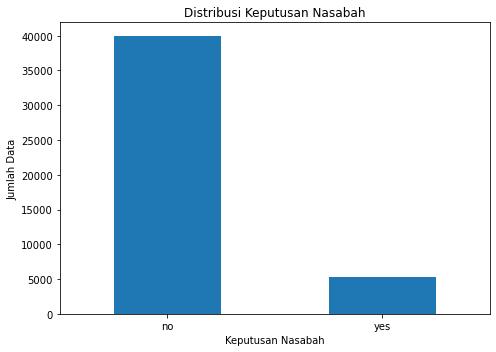

In [8]:
# 202431076_AimeeJehovaJireh

# Membaca dataset yang sudah diekstrak
df = pd.read_csv(
    "bank_customers.csv",
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

# Merapikan nama kolom
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.replace("\ufeff", "", regex=False)
    .str.lower()
)

# Memastikan kolom target tersedia
if "y" not in df.columns:
    raise ValueError(
        f"Kolom target 'y' tidak ditemukan. "
        f"Kolom yang tersedia: {df.columns.tolist()}"
    )

# Menghitung distribusi target
target_counts = (
    df["y"].astype(str).str.strip().str.lower().value_counts()
)

print("Distribusi Variabel Target:")
display(target_counts.reindex(["no", "yes"], fill_value=0))

# Membuat grafik distribusi target
target_counts.reindex(["no", "yes"], fill_value=0).plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Distribusi Keputusan Nasabah")
plt.xlabel("Keputusan Nasabah")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Exploratory Data Analysis (EDA) Fitur Numerik

Statistik Deskriptif Fitur Numerik:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


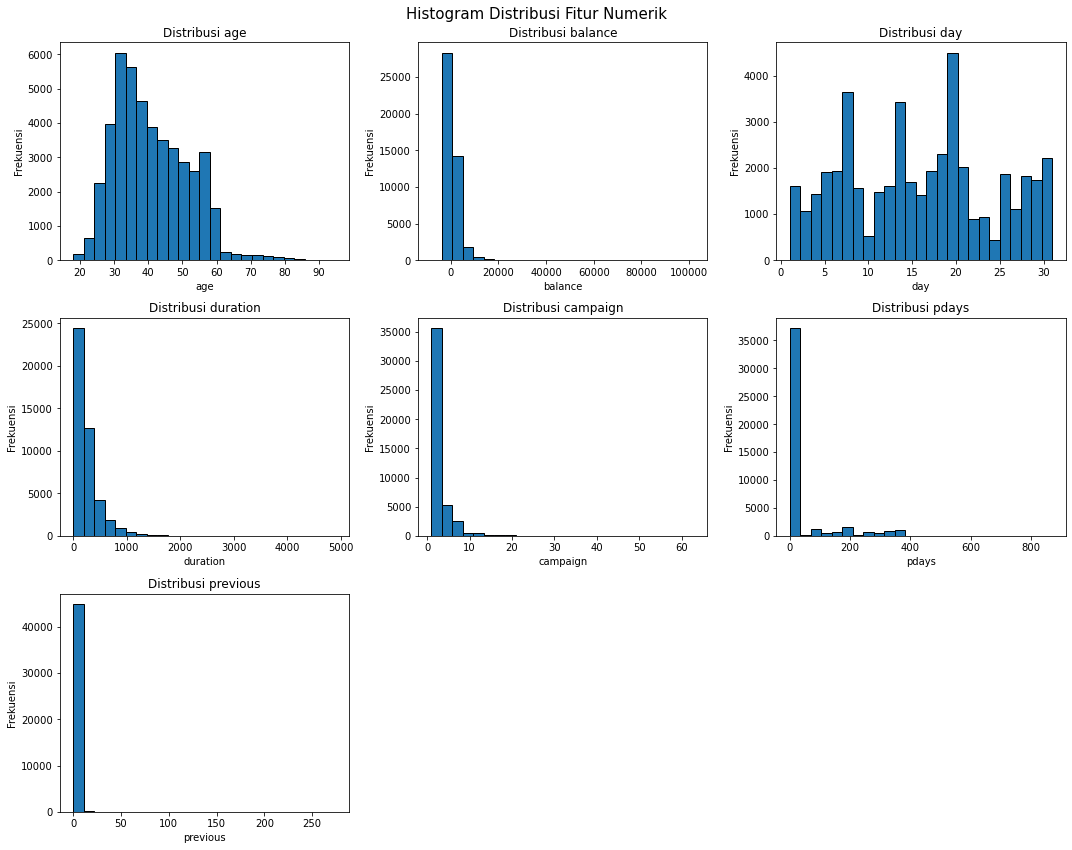

In [10]:
# 202431076_AimeeJehovaJireh

# Mengambil seluruh kolom numerik
numeric_cols = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Menampilkan statistik deskriptif
print("Statistik Deskriptif Fitur Numerik:")
display(df[numeric_cols].describe().T)

# Menentukan jumlah grafik
jumlah_fitur = len(numeric_cols)
jumlah_kolom = 3
jumlah_baris = int(np.ceil(jumlah_fitur / jumlah_kolom))

# Membuat area grafik
fig, axes = plt.subplots(
    jumlah_baris,
    jumlah_kolom,
    figsize=(15, 4 * jumlah_baris)
)

# Mengubah axes menjadi array satu dimensi
axes = np.array(axes).reshape(-1)

# Membuat histogram setiap fitur
for i, kolom in enumerate(numeric_cols):

    data = pd.to_numeric(
        df[kolom],
        errors="coerce"
    ).dropna()

    axes[i].hist(
        data,
        bins=25,
        edgecolor="black"
    )

    axes[i].set_title(f"Distribusi {kolom}")
    axes[i].set_xlabel(kolom)
    axes[i].set_ylabel("Frekuensi")

# Menghapus area grafik yang tidak digunakan
for j in range(jumlah_fitur, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Histogram Distribusi Fitur Numerik",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Exploratory Data Analysis (EDA) Fitur Kategorikal

In [11]:
# 202431076_AimeeJehovaJireh

categorical_cols = df.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Mengeluarkan target dari analisis fitur
categorical_cols = [
    kolom for kolom in categorical_cols
    if kolom != "y"
]

for kolom in categorical_cols:

    print("\nDistribusi Kategori:", kolom)

    display(
        df[kolom]
        .value_counts()
        .head(15)
    )


Distribusi Kategori: job


job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


Distribusi Kategori: marital


marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64


Distribusi Kategori: education


education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

... (8 outputs left out)


Distribusi Kategori: month


month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count, dtype: int64


Distribusi Kategori: poutcome


poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

# Menentukan Fitur dan Target

In [12]:
# 202431076_AimeeJehovaJireh

# Mengubah target menjadi angka
y = (
    df["y"]
    .map({"no": 0, "yes": 1})
    .astype(int)
)

# Menghapus target dan duration dari fitur
X = df.drop(
    columns=["y", "duration"]
)

print("Ukuran Fitur:", X.shape)
print("Ukuran Target:", y.shape)

print("\nDistribusi Target:")
display(y.value_counts())

Ukuran Fitur: (45211, 15)
Ukuran Target: (45211,)

Distribusi Target:


y
0    39922
1     5289
Name: count, dtype: int64

# Memisahkan Fitur Numerik dan Kategorikal

In [13]:
# 202431076_AimeeJehovaJireh

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Fitur Numerik:")
print(numeric_features)

print("\nFitur Kategorikal:")
print(categorical_features)

print("\nJumlah Fitur Numerik:", len(numeric_features))
print("Jumlah Fitur Kategorikal:", len(categorical_features))

Fitur Numerik:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Fitur Kategorikal:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Jumlah Fitur Numerik: 6
Jumlah Fitur Kategorikal: 9


# Membagi Data Latih dan Data Uji

In [14]:
# 202431076_AimeeJehovaJireh

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah Data Latih:", len(X_train))
print("Jumlah Data Uji:", len(X_test))

print("\nDistribusi Data Latih:")
display(y_train.value_counts())

print("\nDistribusi Data Uji:")
display(y_test.value_counts())

Jumlah Data Latih: 36168
Jumlah Data Uji: 9043

Distribusi Data Latih:


y
0    31937
1     4231
Name: count, dtype: int64


Distribusi Data Uji:


y
0    7985
1    1058
Name: count, dtype: int64

# Membuat Preprocessing Pipeline

In [16]:
# 202431076_AimeeJehovaJireh

# Pipeline fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan seluruh preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline berhasil dibuat.")

Preprocessing pipeline berhasil dibuat.


# Melatih Model Linear Regression

In [17]:
# 202431076_AimeeJehovaJireh

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Melatih model
linear_model.fit(X_train, y_train)

# Prediksi data uji
linear_pred = linear_model.predict(X_test)

# Mengubah prediksi menjadi kelas
linear_class = (
    linear_pred >= 0.5
).astype(int)

print("Lima Prediksi Linear Regression:")
print(linear_pred[:5])

print("\nLima Kelas Prediksi:")
print(linear_class[:5])

Lima Prediksi Linear Regression:
[-0.03588867  0.01313782  0.03382874 -0.01035309  0.1343689 ]

Lima Kelas Prediksi:
[0 0 0 0 0]


# Evaluasi Model Linear Regression

In [18]:
# 202431076_AimeeJehovaJireh

# Evaluasi regresi
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_pred)

# Evaluasi klasifikasi
linear_accuracy = accuracy_score(y_test, linear_class)

linear_precision = precision_score(
    y_test, linear_class, zero_division=0
)

linear_recall = recall_score(
    y_test, linear_class, zero_division=0
)

linear_f1 = f1_score(
    y_test, linear_class, zero_division=0
)

print("EVALUASI LINEAR REGRESSION")
print("--------------------------------")
print("MAE      :", linear_mae)
print("MSE      :", linear_mse)
print("RMSE     :", linear_rmse)
print("R2       :", linear_r2)
print("Accuracy :", linear_accuracy)
print("Precision:", linear_precision)
print("Recall   :", linear_recall)
print("F1-Score :", linear_f1)

print("\nRentang Prediksi:")
print(linear_pred.min(), "sampai", linear_pred.max())

EVALUASI LINEAR REGRESSION
--------------------------------
MAE      : 0.17468863262297582
MSE      : 0.0859439304723059
RMSE     : 0.2931619526342153
R2       : 0.16808360184208992
Accuracy : 0.8929558774742895
Precision: 0.6470588235294118
Recall   : 0.18714555765595464
F1-Score : 0.2903225806451613

Rentang Prediksi:
-0.2149505615234375 sampai 0.9317550659179688


# Melatih Model Decision Tree

In [19]:
# 202431076_AimeeJehovaJireh

tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

# Melatih model
tree_model.fit(X_train, y_train)

# Melakukan prediksi
tree_pred = tree_model.predict(X_test)

print("Lima Prediksi Decision Tree:")
print(tree_pred[:5])

Lima Prediksi Decision Tree:
[0 0 0 0 0]


# Evaluasi Model Decision Tree

In [20]:
# 202431076_AimeeJehovaJireh

tree_accuracy = accuracy_score(y_test, tree_pred)

tree_precision = precision_score(
    y_test, tree_pred, zero_division=0
)

tree_recall = recall_score(
    y_test, tree_pred, zero_division=0
)

tree_f1 = f1_score(
    y_test, tree_pred, zero_division=0
)

print("EVALUASI DECISION TREE")
print("--------------------------------")
print("Accuracy :", tree_accuracy)
print("Precision:", tree_precision)
print("Recall   :", tree_recall)
print("F1-Score :", tree_f1)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        tree_pred,
        target_names=["no", "yes"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tree_pred))

EVALUASI DECISION TREE
--------------------------------
Accuracy : 0.8324671016255667
Precision: 0.35955746773202213
Recall   : 0.552930056710775
F1-Score : 0.43575418994413406

Classification Report:
              precision    recall  f1-score   support

          no       0.94      0.87      0.90      7985
         yes       0.36      0.55      0.44      1058

    accuracy                           0.83      9043
   macro avg       0.65      0.71      0.67      9043
weighted avg       0.87      0.83      0.85      9043


Confusion Matrix:
[[6943 1042]
 [ 473  585]]


# Visualisasi Confusion Matrix

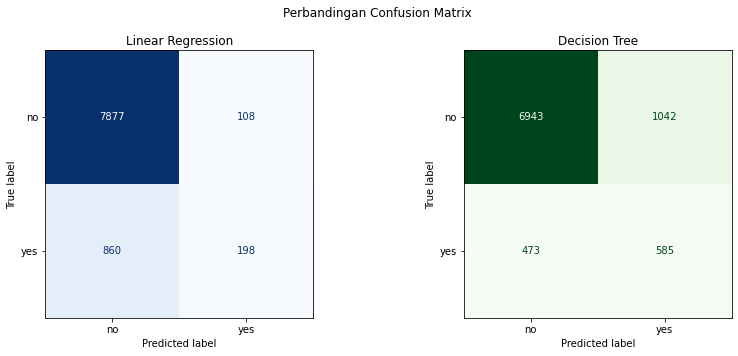

In [22]:
# 202431076_AimeeJehovaJireh

# Menghitung Confusion Matrix masing-masing model
cm_linear = confusion_matrix(y_test, linear_class)
cm_tree = confusion_matrix(y_test, tree_pred)

# Membuat area visualisasi
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix Linear Regression
disp_linear = ConfusionMatrixDisplay(
    confusion_matrix=cm_linear,
    display_labels=["no", "yes"]
)

disp_linear.plot(
    ax=axes[0],
    colorbar=False,
    cmap="Blues"
)

axes[0].set_title("Linear Regression")

# Confusion Matrix Decision Tree
disp_tree = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=["no", "yes"]
)

disp_tree.plot(
    ax=axes[1],
    colorbar=False,
    cmap="Greens"
)

axes[1].set_title("Decision Tree")

# Judul utama
plt.suptitle("Perbandingan Confusion Matrix")

plt.tight_layout()
plt.show()

# Perbandingan Hasil Linear Regression dan Decision Tree

In [26]:
# Watermark NIM: 202431076_AimeeJehovaJireh

# Membuat tabel perbandingan hasil evaluasi
hasil_perbandingan = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        linear_accuracy,
        tree_accuracy
    ],
    "Precision": [
        linear_precision,
        tree_precision
    ],
    "Recall": [
        linear_recall,
        tree_recall
    ],
    "F1-Score": [
        linear_f1,
        tree_f1
    ]
})

# Menampilkan tabel perbandingan
print("TABEL PERBANDINGAN HASIL EVALUASI MODEL")
display(hasil_perbandingan.round(4))


# Membandingkan nilai setiap metrik
print("\nANALISIS HASIL PERBANDINGAN")
print("=" * 45)

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

for metric in metrics:
    nilai_linear = hasil_perbandingan.loc[
        0, metric
    ]

    nilai_tree = hasil_perbandingan.loc[
        1, metric
    ]

    if nilai_linear > nilai_tree:
        terbaik = "Linear Regression"
    elif nilai_tree > nilai_linear:
        terbaik = "Decision Tree"
    else:
        terbaik = "Keduanya memiliki nilai yang sama"

    print(f"{metric}: {terbaik}")


# Menentukan model berdasarkan F1-Score
if linear_f1 > tree_f1:
    model_terbaik = "Linear Regression"
elif tree_f1 > linear_f1:
    model_terbaik = "Decision Tree"
else:
    model_terbaik = "Keduanya memiliki nilai F1-Score yang sama"

print("\nKESIMPULAN:")
print("Model dengan F1-Score tertinggi adalah:", model_terbaik)

TABEL PERBANDINGAN HASIL EVALUASI MODEL


,Model,Accuracy,Precision,Recall,F1-Score
0,Linear Regression,0.8930,0.6471,0.1871,0.2903
1,Decision Tree,0.8325,0.3596,0.5529,0.4358



ANALISIS HASIL PERBANDINGAN
Accuracy: Linear Regression
Precision: Linear Regression
Recall: Decision Tree
F1-Score: Decision Tree

KESIMPULAN:
Model dengan F1-Score tertinggi adalah: Decision Tree
